In [1]:
!pip install pandas numpy matplotlib scikit-learn nltk

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 1.7/1.7 MB 164.6 kB/s eta 0:00:00



[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import os



Question 1

In [5]:
import os
import pandas as pd

folder_path = r"C:\Users\Prapti\OneDrive\Desktop\ML2\ML assignments\eng_-french.csv"

print(os.listdir(folder_path))

['eng_-french.csv']


In [6]:
dataset_path = os.path.join(folder_path, "eng_-french.csv")

df = pd.read_csv(dataset_path)

print("Dataset loadeded successfully!")
print("Shape",df.shape)
print("Columns",df.columns)
df.head(10)

Dataset loadeded successfully!
Shape (175621, 2)
Columns Index(['English words/sentences', 'French words/sentences'], dtype='str')


,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !
5,Fire!,Au feu !
6,Help!,À l'aide !
7,Jump.,Saute.
8,Stop!,Ça suffit !
9,Stop!,Stop !


In [7]:
df.sample(10,random_state=42)

,English words/sentences,French words/sentences
2785,Take a seat.,Prends place !
29880,I wish Tom was here.,J'aimerais que Tom soit là.
53776,How did the audition go?,Comment s'est passée l'audition ?
154386,I've no friend to talk to about my problems.,Je n'ai pas d'ami avec lequel je puisse m'entr...
149823,I really like this skirt. Can I try it on?,"J'aime beaucoup cette jupe, puis-je l'essayer ?"
38625,What happened to him?,Que lui est-il arrivé ?
85226,Take any two cards you like.,Prends deux cartes de ton choix.
42431,I'm not scared to die.,Je ne crains pas de mourir.
43799,The clock has stopped.,L'horloge s'est arrêtée.
143051,You'd better make sure that it is true.,Tu ferais bien de t'assurer que c'est vrai.


In [8]:
print("Dataset Information:")
print(df.info())

print("\n Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\n Dataset shape:")
print(df.shape)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 175621 entries, 0 to 175620
Data columns (total 2 columns):
 #   Column                   Non-Null Count   Dtype
---  ------                   --------------   -----
 0   English words/sentences  175621 non-null  str  
 1   French words/sentences   175621 non-null  str  
dtypes: str(2)
memory usage: 14.1 MB
None

 Missing values
English words/sentences    0
French words/sentences     0
dtype: int64

Duplicate rows:
0

 Dataset shape:
(175621, 2)


In [9]:
df['English_Length']=df['English words/sentences'].apply(lambda x:len(str(x).split()))
df['French_Length']=df['French words/sentences'].apply(lambda x:len(str(x).split()))

print("English sentence length:")
print(df['English_Length'].describe())

print("\n French sentence length")
print(df['French_Length'].describe())

English sentence length:
count    175621.000000
mean          6.161552
std           2.485664
min           1.000000
25%           4.000000
50%           6.000000
75%           7.000000
max          44.000000
Name: English_Length, dtype: float64

 French sentence length
count    175621.000000
mean          6.706669
std           2.789074
min           1.000000
25%           5.000000
50%           6.000000
75%           8.000000
max          55.000000
Name: French_Length, dtype: float64


In [10]:
import re
import unicodedata
def clean_sentence(sentence):
    sentence=sentence.lower()
    sentence=unicodedata.normalize('NFC',sentence)
    sentence=re.sub(r'\s',' ',sentence).strip()
    return sentence

In [11]:
df['English_Clean']=df['English words/sentences'].apply(clean_sentence)
df['French_Clean']=df['French words/sentences'].apply(clean_sentence)


In [12]:
df[['English words/sentences',
    'English_Clean',
    'French words/sentences',
    'French_Clean']].head(10)

,English words/sentences,English_Clean,French words/sentences,French_Clean
0,Hi.,hi.,Salut!,salut!
1,Run!,run!,Cours !,cours !
2,Run!,run!,Courez !,courez !
3,Who?,who?,Qui ?,qui ?
4,Wow!,wow!,Ça alors !,ça alors !
5,Fire!,fire!,Au feu !,au feu !
6,Help!,help!,À l'aide !,à l'aide !
7,Jump.,jump.,Saute.,saute.
8,Stop!,stop!,Ça suffit !,ça suffit !
9,Stop!,stop!,Stop !,stop !


In [13]:
print("Original English:",df['English words/sentences'][0])
print("Cleaned English",df['English_Clean'][0])

print("Original French:",df['French words/sentences'][0])
print("Cleaned French",df['French_Clean'][0])

Original English: Hi.
Cleaned English hi.
Original French: Salut!
Cleaned French salut!


In [14]:
def tokenize(sentence):
    return re.findall(r"\w+|[^\w\s]",sentence,flags=re.UNICODE)

In [15]:
df['English_Tokens']=df['English_Clean'].apply(tokenize)
df['French_Tokens']=df['French_Clean'].apply(tokenize)


In [16]:
for i in range(10):
    print("English Sentence:",df['English_Clean'][i])
    print("English Tokens:",df['English_Tokens'][i])

    print("French Sentence:",df['French_Clean'][i])

    print("French Tokens:",df['French_Tokens'][i])

    print("-"*60) 

English Sentence: hi.
English Tokens: ['hi', '.']
French Sentence: salut!
French Tokens: ['salut', '!']
------------------------------------------------------------
English Sentence: run!
English Tokens: ['run', '!']
French Sentence: cours !
French Tokens: ['cours', '!']
------------------------------------------------------------
English Sentence: run!
English Tokens: ['run', '!']
French Sentence: courez !
French Tokens: ['courez', '!']
------------------------------------------------------------
English Sentence: who?
English Tokens: ['who', '?']
French Sentence: qui ?
French Tokens: ['qui', '?']
------------------------------------------------------------
English Sentence: wow!
English Tokens: ['wow', '!']
French Sentence: ça alors !
French Tokens: ['ça', 'alors', '!']
------------------------------------------------------------
English Sentence: fire!
English Tokens: ['fire', '!']
French Sentence: au feu !
French Tokens: ['au', 'feu', '!']
------------------------------------------

In [17]:
df['English_Token_Count']=df['English_Tokens'].apply(len)
df['French_Token_Count']=df['French_Tokens'].apply(len)
print("Average English tokens:",df['English_Token_Count'].mean())
print("Average French tokens",df['French_Token_Count'].mean())

Average English tokens: 7.956030315281202
Average French tokens 8.981329112122127


In [18]:
PAD_TOKEN="<PAD>"
SOS_TOKEN="<SOS>"
EOS_TOKEN="<EOS>"
UNK_TOKEN="<UNK>"

special_tokens=[PAD_TOKEN,SOS_TOKEN,EOS_TOKEN,UNK_TOKEN]
PAD_IDX=0
SOS_IDX=1
EOS_IDX=2
UNK_IDX=3

In [19]:
from collections import Counter
english_counter=Counter()
for tokens in df['English_Tokens']:
    english_counter.update(tokens)
english_vocab={
    token:idx
    for idx,token in enumerate(special_tokens)
}

for token, count in english_counter.items():
    if token not in english_vocab:
        english_vocab[token]=len(english_vocab)
print("English Vocabalary Size",len(english_vocab))

English Vocabalary Size 14138


In [20]:
french_counter=Counter()
for tokens in df['French_Tokens']:
    french_counter.update(tokens)
french_vocab={
    token:idx
    for idx,token in enumerate(special_tokens)
}

for token, count in french_counter.items():
    if token not in french_vocab:
        french_vocab[token]=len(french_vocab)
print("French Vocabalary Size",len(french_vocab))

French Vocabalary Size 24210


In [21]:
print("English vocabalary(first 20)")
for word,idx in list(english_vocab.items())[:20]:
    print(word,":",idx)
print("\n french vocabalary(first 20)")
for word,idx in list(french_vocab.items())[:20]:
    print(word,":",idx)

English vocabalary(first 20)
<PAD> : 0
<SOS> : 1
<EOS> : 2
<UNK> : 3
hi : 4
. : 5
run : 6
! : 7
who : 8
? : 9
wow : 10
fire : 11
help : 12
jump : 13
stop : 14
wait : 15
go : 16
on : 17
hello : 18
i : 19

 french vocabalary(first 20)
<PAD> : 0
<SOS> : 1
<EOS> : 2
<UNK> : 3
salut : 4
! : 5
cours : 6
courez : 7
qui : 8
? : 9
ça : 10
alors : 11
au : 12
feu : 13
à : 14
l : 15
' : 16
aide : 17
saute : 18
. : 19


In [22]:
english_idx_to_word={
    idx:word
    for word,idx in english_vocab.items()
}

french_idx_to_word={
    idx:word
    for word,idx in french_vocab.items()
}


In [23]:
print("Special Token IDs")
for token in special_tokens:
    print(token,":",english_vocab[token])
print("\n French Special Token IDs:")
for token in special_tokens:
    print(token,":",french_vocab[token])
    

Special Token IDs
<PAD> : 0
<SOS> : 1
<EOS> : 2
<UNK> : 3

 French Special Token IDs:
<PAD> : 0
<SOS> : 1
<EOS> : 2
<UNK> : 3


In [24]:
def encode_sentence(tokens,vocab):
    encoded=[]
    for token in tokens:
        token_id=vocab.get(token,UNK_IDX)
        encoded.append(token_id)
    return encoded

In [25]:
df['English_Encoded']=df['English_Tokens'].apply(lambda tokens: encode_sentence(tokens,english_vocab))


In [26]:
df['French_Encoded']=df['French_Tokens'].apply(lambda tokens: encode_sentence(tokens,french_vocab))


In [27]:
def add_special_tokens(encoded,add_sos=False):
    if add_sos:
        return[SOS_IDX]+encoded+[EOS_IDX]
    return encoded + [EOS_IDX]

In [28]:
df['English_Encoded']=df['English_Encoded'].apply(lambda x:add_special_tokens(x))
df['French_Encoded']=df['French_Encoded'].apply(lambda x:add_special_tokens(x,add_sos=True))


In [29]:
for i in range(5):
    print("English:",df['English_Clean'][i])
    print("English IDs:",df['English_Encoded'][i])
    
    print("French",df['French_Clean'][i])
    print("French IDs",df['French_Encoded'][i])
    
    print("-"*60)

English: hi.
English IDs: [4, 5, 2]
French salut!
French IDs [1, 4, 5, 2]
------------------------------------------------------------
English: run!
English IDs: [6, 7, 2]
French cours !
French IDs [1, 6, 5, 2]
------------------------------------------------------------
English: run!
English IDs: [6, 7, 2]
French courez !
French IDs [1, 7, 5, 2]
------------------------------------------------------------
English: who?
English IDs: [8, 9, 2]
French qui ?
French IDs [1, 8, 9, 2]
------------------------------------------------------------
English: wow!
English IDs: [10, 7, 2]
French ça alors !
French IDs [1, 10, 11, 5, 2]
------------------------------------------------------------


In [30]:
print("English Vocabalary Size",len(english_vocab))
print("French Vocabalary Size",len(french_vocab))

English Vocabalary Size 14138
French Vocabalary Size 24210


In [31]:
MAX_LEN=30

In [32]:
def pad_or_truncate(sequence,max_len):
    if len(sequence)>max_len:
        sequence=sequence[:max_len]
        sequence[-1]=EOS_IDX
    else:
        sequence=sequence+[PAD_IDX]*(max_len-len(sequence))
    return sequence

In [33]:
df['English_Padded']=df['English_Encoded'].apply(lambda x: pad_or_truncate(x,MAX_LEN))

In [34]:
df['French_Padded']=df['French_Encoded'].apply(lambda x: pad_or_truncate(x,MAX_LEN))

In [35]:
for i in range(5):
    print("English",df['English_Clean'][i])
    print("English Encoded:",df['English_Encoded'][i])
    print("English_Padded:",df['English_Padded'][i])
    
    print("French",df['French_Clean'][i])
    print("French Encoded:",df['French_Encoded'][i])
    print("French_Padded:",df['French_Padded'][i])
    
    print("-"*80)

English hi.
English Encoded: [4, 5, 2]
English_Padded: [4, 5, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
French salut!
French Encoded: [1, 4, 5, 2]
French_Padded: [1, 4, 5, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
--------------------------------------------------------------------------------
English run!
English Encoded: [6, 7, 2]
English_Padded: [6, 7, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
French cours !
French Encoded: [1, 6, 5, 2]
French_Padded: [1, 6, 5, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
--------------------------------------------------------------------------------
English run!
English Encoded: [6, 7, 2]
English_Padded: [6, 7, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
French courez !
French Encoded: [1, 7, 5, 2]
French_Padded: [1, 7, 5, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [36]:
print("English padded lengths")
print(df['English_Padded'].apply(len).value_counts())
print("\n French padded lengths:")
print(df['French_Padded'].apply(len).value_counts())

English padded lengths
English_Padded
30    175621
Name: count, dtype: int64

 French padded lengths:
French_Padded
30    175621
Name: count, dtype: int64


In [37]:
english_truncated=sum(len(x)>MAX_LEN for x in df['English_Encoded'])
french_truncated=sum(len(x)>MAX_LEN for x in df['French_Encoded'])
print("English sentences truncated",english_truncated)
print("French sentences truncated",french_truncated)

English sentences truncated 40
French sentences truncated 150


In [38]:
X=np.array(df['English_Padded'].tolist(),dtype=np.int32)
Y=np.array(df['French_Padded'].tolist(),dtype=np.int32)
print("English data shape",X.shape)
print("French data shape",Y.shape)

English data shape (175621, 30)
French data shape (175621, 30)


In [39]:
from sklearn.model_selection import train_test_split
train_df,temp_df=train_test_split(df,test_size=0.20,random_state=42,shuffle=True)

val_df,test_df=train_test_split(temp_df,test_size=0.20,random_state=42,shuffle=True)

In [40]:
print("Original Dataset",len(df))
print("\n Training dataset",len(train_df))
print("Validation Dataset",len(val_df))
print("Testing Dataset",len(test_df))

Original Dataset 175621

 Training dataset 140496
Validation Dataset 28100
Testing Dataset 7025


In [41]:
total=len(df)
print("Training",len(train_df)/total*100,"%")
print("Validation",len(val_df)/total*100,"%")
print("Testing",len(test_df)/total*100,"%")

Training 79.99954447361078 %
Validation 16.00036442111137 %
Testing 4.000091105277843 %


In [42]:
from collections import Counter

english_counter = Counter()

for tokens in train_df['English_Tokens']:
    english_counter.update(tokens)

english_vocab = {
    token: idx
    for idx, token in enumerate(special_tokens)
}

for token in english_counter:
    if token not in english_vocab:
        english_vocab[token] = len(english_vocab)

print("English Vocabulary Size:", len(english_vocab))

English Vocabulary Size: 13182


In [43]:
french_counter = Counter()

for tokens in train_df['French_Tokens']:
    french_counter.update(tokens)

french_vocab = {
    token: idx
    for idx, token in enumerate(special_tokens)
}

for token in french_counter:
    if token not in french_vocab:
        french_vocab[token] = len(french_vocab)

print("French Vocabulary Size:", len(french_vocab))

French Vocabulary Size: 22329


In [44]:
english_idx_to_word = {
    idx: word for word, idx in english_vocab.items()
}

french_idx_to_word = {
    idx: word for word, idx in french_vocab.items()
}

In [45]:
def prepare_data(data, vocab, add_sos=False):

    encoded_data = []

    for tokens in data:

        encoded = encode_sentence(tokens, vocab)

        if add_sos:
            encoded = [SOS_IDX] + encoded

        encoded.append(EOS_IDX)

        encoded = pad_or_truncate(encoded, MAX_LEN)

        encoded_data.append(encoded)

    return np.array(encoded_data, dtype=np.int32)

In [46]:
X_train = prepare_data(train_df['English_Tokens'], english_vocab)
Y_train = prepare_data(train_df['French_Tokens'], french_vocab, True)

X_val = prepare_data(val_df['English_Tokens'], english_vocab)
Y_val = prepare_data(val_df['French_Tokens'], french_vocab, True)

X_test = prepare_data(test_df['English_Tokens'], english_vocab)
Y_test = prepare_data(test_df['French_Tokens'], french_vocab, True)

In [47]:
print("Training Shapes:")
print("English:", X_train.shape)
print("French:", Y_train.shape)

print("\nValidation Shapes:")
print("English:", X_val.shape)
print("French:", Y_val.shape)

print("\nTesting Shapes:")
print("English:", X_test.shape)
print("French:", Y_test.shape)

Training Shapes:
English: (140496, 30)
French: (140496, 30)

Validation Shapes:
English: (28100, 30)
French: (28100, 30)

Testing Shapes:
English: (7025, 30)
French: (7025, 30)


Question 2

In [48]:
import tensorflow as tf
from tensorflow.keras.layers import Embedding,LSTM
from tensorflow.keras import Model
print("TensorFlow version",tf.__version__)

TensorFlow version 2.21.0


In [49]:
VOCAB_SIZE=len(english_vocab)
print("English Vocabulary size",VOCAB_SIZE)

English Vocabulary size 13182


In [50]:
import tensorflow as tf
from tensorflow.keras.layers import Embedding,LSTM,Input
from tensorflow.keras import Model
EMBEDDING_DIM=128
LSTM_UNITS=256
MAX_LENGTH=30

encoder_inputs=Input(shape=(MAX_LENGTH,),name="encoder_inputs")
encoder_embedding=Embedding(input_dim=VOCAB_SIZE,output_dim=EMBEDDING_DIM,name="encoder_embedding")

embedded_inputs=encoder_embedding(encoder_inputs)

encoder_lstm=LSTM(LSTM_UNITS,return_sequences=True,return_state=True,dropout=0.0,name="encoder_lstm")

encoder_outputs,state_h,state_c=encoder_lstm(embedded_inputs)
encoder_model=Model(encoder_inputs,[encoder_outputs,state_h,state_c])
encoder_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_inputs (InputLayer)     │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_embedding (Embedding)   │ (None, 30, 128)        │     1,687,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_lstm (LSTM)             │ [(None, 30, 256),      │       394,240 │
│                                 │ (None, 256), (None,    │               │
│                                 │ 256)]                  │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,081,536 (7.94 MB)

 Trainable params: 2,081,536 (7.94 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
sample_input=X_train[:2]
outputs,hidden_state,cell_state=encoder_model.predict(sample_input)
print("Input Shape",sample_input.shape)
print("Encoder Output Shape",outputs.shape)
print("Hidden state shape",hidden_state.shape)
print("Cell state shape",cell_state.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Input Shape (2, 30)
Encoder Output Shape (2, 30, 256)
Hidden state shape (2, 256)
Cell state shape (2, 256)


Question 3

In [53]:
FRENCH_VOCAB_SIZE=len(french_vocab)
print("French Vocabulary Size",FRENCH_VOCAB_SIZE)


French Vocabulary Size 22329


In [54]:
from tensorflow.keras.layers import Input
decoder_inputs=Input(shape=(MAX_LENGTH,),name="decoder_inputs")

In [55]:
from tensorflow.keras.layers import Embedding
decoder_embedding_layer=Embedding(input_dim=FRENCH_VOCAB_SIZE,output_dim=EMBEDDING_DIM,name="decoder_embedding")

decoder_embedded=decoder_embedding_layer(decoder_inputs)

In [56]:
from tensorflow.keras.layers import LSTM
decoder_lstm=LSTM(LSTM_UNITS,return_sequences=True,return_state=True,dropout=0.0,name="decoder_lstm")

In [57]:
state_h_input = Input(
    shape=(LSTM_UNITS,),
    name="decoder_initial_hidden_state"
)

state_c_input = Input(
    shape=(LSTM_UNITS,),
    name="decoder_initial_cell_state"
)

In [58]:
decoder_outputs, decoder_state_h, decoder_state_c = decoder_lstm(
    decoder_embedded,
    initial_state=[state_h_input, state_c_input]
)

In [59]:
from tensorflow.keras.layers import Dense
decoder_dense=Dense(FRENCH_VOCAB_SIZE,activation="softmax",name="decoder_output")

decoder_predictions=decoder_dense(decoder_outputs)

In [60]:
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model

decoder_inputs = Input(
    shape=(MAX_LENGTH,),
    name="decoder_inputs"
)
state_h_input = Input(
    shape=(LSTM_UNITS,),
    name="decoder_initial_hidden_state"
)

state_c_input = Input(
    shape=(LSTM_UNITS,),
    name="decoder_initial_cell_state"
)

decoder_embedding_layer = Embedding(
    input_dim=FRENCH_VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    name="decoder_embedding"
)

decoder_embedded = decoder_embedding_layer(decoder_inputs)

decoder_lstm = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0,
    name="decoder_lstm"
)

decoder_outputs, decoder_state_h, decoder_state_c = decoder_lstm(
    decoder_embedded,
    initial_state=[state_h_input, state_c_input]
)

decoder_dense = Dense(
    FRENCH_VOCAB_SIZE,
    activation="softmax",
    name="decoder_output"
)

decoder_predictions = decoder_dense(decoder_outputs)

decoder_model = Model(
    inputs=[decoder_inputs, state_h_input, state_c_input],
    outputs=[decoder_predictions, decoder_state_h, decoder_state_c]
)

decoder_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_inputs      │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 30, 128)   │  2,858,112 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_initial_hi… │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_initial_ce… │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 30, 256), │    394,240 │ decoder_embeddin… │
│                     │ (None, 256),      │            │ decoder_initial_… │
│                     │ (None, 256)]      │            │ decoder_initial_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, 30, 22329) │  5,738,553 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,990,905 (34.30 MB)

 Trainable params: 8,990,905 (34.30 MB)

 Non-trainable params: 0 (0.00 B)

Question 4

In [61]:

required_variables = [
    "X_train",
    "X_val",
    "X_test",
    "Y_train",
    "Y_val",
    "Y_test",
    "english_vocab",
    "french_vocab",
    "encoder_embedding",
    "encoder_lstm",
    "decoder_embedding_layer",
    "decoder_lstm",
    "decoder_dense"
]

for variable in required_variables:
    print(f"{variable}: {'Available' if variable in globals() else 'Missing'}")


X_train: Available
X_val: Available
X_test: Available
Y_train: Available
Y_val: Available
Y_test: Available
english_vocab: Available
french_vocab: Available
encoder_embedding: Available
encoder_lstm: Available
decoder_embedding_layer: Available
decoder_lstm: Available
decoder_dense: Available


In [62]:
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_val:", X_val.shape)
print("Y_val:", Y_val.shape)

X_train: (140496, 30)
Y_train: (140496, 30)
X_val: (28100, 30)
Y_val: (28100, 30)


In [63]:
decoder_input_train = Y_train[:, :-1]
decoder_target_train = Y_train[:, 1:]

decoder_input_val = Y_val[:, :-1]
decoder_target_val = Y_val[:, 1:]

decoder_input_test = Y_test[:, :-1]
decoder_target_test = Y_test[:, 1:]

print("Decoder Input Train:", decoder_input_train.shape)
print("Decoder Target Train:", decoder_target_train.shape)

print("Decoder Input Validation:", decoder_input_val.shape)
print("Decoder Target Validation:", decoder_target_val.shape)

print("Decoder Input Test:", decoder_input_test.shape)
print("Decoder Target Test:", decoder_target_test.shape)


Decoder Input Train: (140496, 29)
Decoder Target Train: (140496, 29)
Decoder Input Validation: (28100, 29)
Decoder Target Validation: (28100, 29)
Decoder Input Test: (7025, 29)
Decoder Target Test: (7025, 29)


In [64]:


EMBEDDING_DIM = 128
LSTM_UNITS = 256

BATCH_SIZE = 64
EPOCHS = 10

LEARNING_RATE = 0.001
TEACHER_FORCING_RATIO = 0.5

PAD_ID = french_vocab["<PAD>"]

print("Embedding Dimension:", EMBEDDING_DIM)
print("LSTM Units:", LSTM_UNITS)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Teacher Forcing Ratio:", TEACHER_FORCING_RATIO)
print("PAD ID:", PAD_ID)

Embedding Dimension: 128
LSTM Units: 256
Batch Size: 64
Epochs: 10
Learning Rate: 0.001
Teacher Forcing Ratio: 0.5
PAD ID: 0


In [65]:

import tensorflow as tf
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=False,
    reduction="none"
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)
print("Loss Function:", loss_function.name)
print("From Logits:", loss_function.get_config()["from_logits"])
print("Optimizer:", optimizer.__class__.__name__)
print("Learning Rate:", LEARNING_RATE)


Loss Function: sparse_categorical_crossentropy
From Logits: False
Optimizer: Adam
Learning Rate: 0.001


In [66]:

train_sample_weights = (
    decoder_target_train != PAD_ID
).astype("float32")

val_sample_weights = (
    decoder_target_val != PAD_ID
).astype("float32")

print("Training Mask Shape:", train_sample_weights.shape)
print("Validation Mask Shape:", val_sample_weights.shape)

print("\nSample Target:")
print(decoder_target_train[0])

print("\nSample Mask:")
print(train_sample_weights[0])


Training Mask Shape: (140496, 29)
Validation Mask Shape: (28100, 29)

Sample Target:
[ 4  5  6  7  8  9 10 11 12  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0]

Sample Mask:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0.]


In [67]:

@tf.function
def train_batch(english_input, french_input, french_target):

    with tf.GradientTape() as tape:

        encoder_embedded = encoder_embedding(english_input)

        _, hidden_state, cell_state = encoder_lstm(
            encoder_embedded,
            training=True
        )

        current_token = french_input[:, 0:1]

        total_loss = 0.0
        total_tokens = 0.0

        for t in range(29):

            embedded_token = decoder_embedding_layer(current_token)

            decoder_output, hidden_state, cell_state = decoder_lstm(
                embedded_token,
                initial_state=[hidden_state, cell_state],
                training=True
            )

            predictions = decoder_dense(decoder_output)
            predictions = tf.squeeze(predictions, axis=1)

            actual_token = french_target[:, t]

            token_loss = loss_function(actual_token, predictions)

            mask = tf.cast(actual_token != PAD_ID, tf.float32)

            total_loss += tf.reduce_sum(token_loss * mask)
            total_tokens += tf.reduce_sum(mask)

            if t < 28:

                predicted_token = tf.argmax(
                    predictions,
                    axis=-1,
                    output_type=tf.int32
                )

                predicted_token = tf.expand_dims(
                    predicted_token, axis=1
                )

                actual_next_token = french_input[:, t+1:t+2]

                use_actual = (
                    tf.random.uniform(
                        shape=tf.shape(actual_next_token),
                        dtype=tf.float32
                    ) < TEACHER_FORCING_RATIO
                )

                current_token = tf.where(
                    use_actual,
                    actual_next_token,
                    predicted_token
                )

        average_loss = tf.math.divide_no_nan(
            total_loss,
            total_tokens
        )

    trainable_variables = (
        encoder_embedding.trainable_variables
        + encoder_lstm.trainable_variables
        + decoder_embedding_layer.trainable_variables
        + decoder_lstm.trainable_variables
        + decoder_dense.trainable_variables
    )

    gradients = tape.gradient(
        average_loss,
        trainable_variables
    )

    optimizer.apply_gradients(
        zip(gradients, trainable_variables)
    )

    return average_loss


In [68]:
sample_loss = train_batch(
    tf.convert_to_tensor(X_train[:64], dtype=tf.int32),
    tf.convert_to_tensor(decoder_input_train[:64], dtype=tf.int32),
    tf.convert_to_tensor(decoder_target_train[:64], dtype=tf.int32)
)

print("Sample Batch Training Loss:", float(sample_loss))
print("Optimizer Iterations:", optimizer.iterations.numpy())

Sample Batch Training Loss: 10.013580322265625
Optimizer Iterations: 1


In [69]:
weights_before = decoder_dense.get_weights()[0].copy()

test_loss = train_batch(
    tf.convert_to_tensor(X_train[64:128], dtype=tf.int32),
    tf.convert_to_tensor(decoder_input_train[64:128], dtype=tf.int32),
    tf.convert_to_tensor(decoder_target_train[64:128], dtype=tf.int32)
)

weights_after = decoder_dense.get_weights()[0]

weight_difference = np.mean(
    np.abs(weights_after - weights_before)
)

print("Training Loss:", float(test_loss))
print("Mean Weight Change:", weight_difference)
print("Optimizer Iterations:", optimizer.iterations.numpy())

Training Loss: 10.010103225708008
Mean Weight Change: 8.8685454e-05
Optimizer Iterations: 2


In [70]:

X_train_tf = tf.convert_to_tensor(X_train, dtype=tf.int32)
X_val_tf = tf.convert_to_tensor(X_val, dtype=tf.int32)

decoder_input_train_tf = tf.convert_to_tensor(
    decoder_input_train, dtype=tf.int32
)
decoder_target_train_tf = tf.convert_to_tensor(
    decoder_target_train, dtype=tf.int32
)

decoder_input_val_tf = tf.convert_to_tensor(
    decoder_input_val, dtype=tf.int32
)
decoder_target_val_tf = tf.convert_to_tensor(
    decoder_target_val, dtype=tf.int32
)

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train_tf, decoder_input_train_tf, decoder_target_train_tf)
).batch(BATCH_SIZE).prefetch(1)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val_tf, decoder_input_val_tf, decoder_target_val_tf)
).batch(BATCH_SIZE).prefetch(1)

print("Training batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))

Training batches: 2196
Validation batches: 440


In [72]:

@tf.function
def evaluate_batch(english_input, french_input, french_target):

    encoder_embedded = encoder_embedding(english_input)

    _, hidden_state, cell_state = encoder_lstm(
        encoder_embedded,
        training=False
    )

    current_token = french_input[:, 0:1]

    total_loss = 0.0
    total_tokens = 0.0

    for t in range(29):

        embedded_token = decoder_embedding_layer(current_token)

        decoder_output, hidden_state, cell_state = decoder_lstm(
            embedded_token,
            initial_state=[hidden_state, cell_state],
            training=False
        )

        predictions = decoder_dense(decoder_output)
        predictions = tf.squeeze(predictions, axis=1)

        actual_token = french_target[:, t]

        token_loss = loss_function(actual_token, predictions)

        mask = tf.cast(actual_token != PAD_ID, tf.float32)

        total_loss += tf.reduce_sum(token_loss * mask)
        total_tokens += tf.reduce_sum(mask)

        if t < 28:

            predicted_token = tf.argmax(
                predictions,
                axis=-1,
                output_type=tf.int32
            )

            current_token = tf.expand_dims(predicted_token, axis=1)

    return tf.math.divide_no_nan(total_loss, total_tokens)


print("Validation function created successfully.")


Validation function created successfully.


In [ ]:

epoch_train_loss = np.mean(batch_losses)

val_batch_losses = []

for english_batch, french_input_batch, french_target_batch in val_dataset:

    loss = evaluate_batch(
        english_batch,
        french_input_batch,
        french_target_batch
    )

    val_batch_losses.append(float(loss))

epoch_val_loss = np.mean(val_batch_losses)

train_losses.append(epoch_train_loss)
val_losses.append(epoch_val_loss)

print("Epoch 1/10")
print("Training Loss:", round(epoch_train_loss, 4))
print("Validation Loss:", round(epoch_val_loss, 4))


Epoch 1/10
Training Loss: 4.562
Validation Loss: 4.5465


In [74]:

import time
import numpy as np

for epoch in range(1, EPOCHS):

    start_time = time.time()

    batch_losses = []

    for english_batch, french_input_batch, french_target_batch in train_dataset:

        loss = train_batch(
            english_batch,
            french_input_batch,
            french_target_batch
        )

        batch_losses.append(float(loss))

    epoch_train_loss = np.mean(batch_losses)

    val_batch_losses = []

    for english_batch, french_input_batch, french_target_batch in val_dataset:

        loss = evaluate_batch(
            english_batch,
            french_input_batch,
            french_target_batch
        )

        val_batch_losses.append(float(loss))

    epoch_val_loss = np.mean(val_batch_losses)

    elapsed = time.time() - start_time

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    epoch_times.append(elapsed)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} - "
        f"Training Loss: {epoch_train_loss:.4f} - "
        f"Validation Loss: {epoch_val_loss:.4f} - "
        f"Time: {elapsed / 60:.2f} minutes"
    )


Epoch 2/10 - Training Loss: 3.5429 - Validation Loss: 4.1278 - Time: 32.90 minutes
Epoch 3/10 - Training Loss: 3.0438 - Validation Loss: 3.7954 - Time: 34.31 minutes
Epoch 4/10 - Training Loss: 2.6590 - Validation Loss: 3.5667 - Time: 31.74 minutes
Epoch 5/10 - Training Loss: 2.3607 - Validation Loss: 3.3861 - Time: 24.85 minutes
Epoch 6/10 - Training Loss: 2.1266 - Validation Loss: 3.2757 - Time: 24.93 minutes
Epoch 7/10 - Training Loss: 1.9370 - Validation Loss: 3.1861 - Time: 24.85 minutes
Epoch 8/10 - Training Loss: 1.7854 - Validation Loss: 3.1585 - Time: 24.47 minutes
Epoch 9/10 - Training Loss: 1.6565 - Validation Loss: 3.1050 - Time: 24.28 minutes
Epoch 10/10 - Training Loss: 1.5497 - Validation Loss: 3.0979 - Time: 24.35 minutes


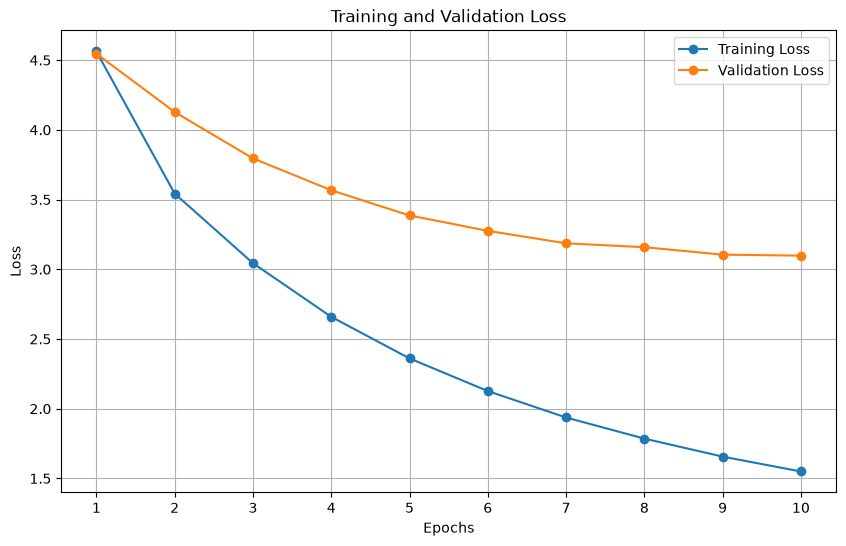

In [75]:

import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    epochs_range,
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.xticks(epochs_range)
plt.legend()
plt.grid(True)

plt.show()


Question 5

In [76]:
english_id_to_word = {
    index: word for word, index in english_vocab.items()
}

french_id_to_word = {
    index: word for word, index in french_vocab.items()
}

SOS_ID = french_vocab["<SOS>"]
EOS_ID = french_vocab["<EOS>"]
PAD_ID = french_vocab["<PAD>"]
UNK_ID = french_vocab["<UNK>"]

print("French SOS ID:", SOS_ID)
print("French EOS ID:", EOS_ID)
print("French PAD ID:", PAD_ID)
print("French UNK ID:", UNK_ID)

French SOS ID: 1
French EOS ID: 2
French PAD ID: 0
French UNK ID: 3


In [77]:

def greedy_decode(english_sequence):

    english_sequence = tf.convert_to_tensor(
        english_sequence.reshape(1, -1),
        dtype=tf.int32
    )

    encoder_embedded = encoder_embedding(english_sequence)

    _, hidden_state, cell_state = encoder_lstm(
        encoder_embedded,
        training=False
    )

    current_token = tf.constant([[SOS_ID]], dtype=tf.int32)

    predicted_tokens = []

    for step in range(MAX_LENGTH):

        embedded_token = decoder_embedding_layer(current_token)

        decoder_output, hidden_state, cell_state = decoder_lstm(
            embedded_token,
            initial_state=[hidden_state, cell_state],
            training=False
        )

        predictions = decoder_dense(decoder_output)

        predicted_id = int(
            tf.argmax(
                predictions[0, 0, :],
                axis=-1
            ).numpy()
        )

        if predicted_id == EOS_ID:
            break

        predicted_tokens.append(predicted_id)

        current_token = tf.constant(
            [[predicted_id]],
            dtype=tf.int32
        )

    translated_words = [
        french_id_to_word.get(token_id, "<UNK>")
        for token_id in predicted_tokens
    ]

    return " ".join(translated_words)


In [78]:
sample_translation = greedy_decode(X_test[0])

print("Predicted French Translation:")
print(sample_translation)

Predicted French Translation:
chaque que je veux être ma vie , ma mère , ma vie est dans un restaurant .


In [79]:

def sequence_to_sentence(sequence, vocabulary):

    words = []

    for token_id in sequence:

        token_id = int(token_id)

        if token_id == PAD_ID:
            break

        if token_id == SOS_ID:
            continue

        if token_id == EOS_ID:
            break

        words.append(vocabulary.get(token_id, "<UNK>"))

    return " ".join(words)



for i in range(10):

    english_sentence = sequence_to_sentence(
        X_test[i],
        english_id_to_word
    )

    reference_french = sequence_to_sentence(
        Y_test[i],
        french_id_to_word
    )

    predicted_french = greedy_decode(X_test[i])

    print(f"\nExample {i + 1}")
    print("English:           ", english_sentence)
    print("Reference French:  ", reference_french)
    print("Predicted French:  ", predicted_french)
    print("-" * 80)



Example 1
English:            whenever i go to a japanese restaurant , i take the disposable chopsticks home with me .
Reference French:   à chaque fois que je vais au restaurant japonais , j ' emporte les baguettes chez moi .
Predicted French:   chaque que je veux être ma vie , ma mère , ma vie est dans un restaurant .
--------------------------------------------------------------------------------

Example 2
English:            she borrowed the book from him many years ago and hasn ' t yet returned it .
Reference French:   elle lui a emprunté le livre il y a de nombreuses années et ne l ' a toujours pas rendu .
Predicted French:   elle a emprunté le livre depuis il y avait trois ans , mais il ne savait .
--------------------------------------------------------------------------------

Example 3
English:            where ' s the dog ?
Reference French:   où est le chien ?
Predicted French:   où est le chien ?
---------------------------------------------------------------------------

In [80]:

import pandas as pd

translation_results = []

for i in range(10):

    english_sentence = sequence_to_sentence(
        X_test[i], english_id_to_word
    )

    reference_french = sequence_to_sentence(
        Y_test[i], french_id_to_word
    )

    predicted_french = greedy_decode(X_test[i])

    translation_results.append({
        "Example": i + 1,
        "English": english_sentence,
        "Reference French": reference_french,
        "Predicted French": predicted_french
    })

results_df = pd.DataFrame(translation_results)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 10)

display(results_df)


,Example,English,Reference French,Predicted French
0,1,"whenever i go to a japanese restaurant , i take the disposable chopsticks home with me .","à chaque fois que je vais au restaurant japonais , j ' emporte les baguettes chez moi .","chaque que je veux être ma vie , ma mère , ma vie est dans un restaurant ."
1,2,she borrowed the book from him many years ago and hasn ' t yet returned it .,elle lui a emprunté le livre il y a de nombreuses années et ne l ' a toujours pas rendu .,"elle a emprunté le livre depuis il y avait trois ans , mais il ne savait ."
2,3,where ' s the dog ?,où est le chien ?,où est le chien ?
3,4,all i want is a washing machine .,"tout ce que je veux , c ' est une machine à laver .",tout ce que je veux me servir de la voiture .
4,5,he is eager to become famous .,il est avide de gloire .,il est devenir devenir célèbre .
5,6,i saw you snickering .,je vous ai vus pouffer .,je vous ai vu pouffer .
6,7,i just love happy endings .,"j ' adore les fins heureuses , un point c ' est tout .",j ' adore juste que les les . .
7,8,he picked up a mirror and looked at his tongue .,il prit un miroir et examina sa langue .,il a un miroir et son le ciel .
8,9,i can imagine how you felt .,je peux imaginer ce que tu as ressenti .,je peux vous entendre comment .
9,10,how long did you stay in boston ?,combien de temps êtes - vous restées à boston ?,combien de temps êtes - vous restés à boston ?


Question 6

In [81]:
results_hidden = [{
    "Hidden Dimension": 256,
    "Training Loss": train_losses[-1],
    "Validation Loss": val_losses[-1],
    "Training Time (min)": sum([
        32.90, 34.31, 31.74, 24.85, 24.93,
        24.85, 24.47, 24.28, 24.35
    ]),
    "Parameters": encoder_model.count_params()
                 + decoder_model.count_params()
}]

In [82]:
HIDDEN_DIM = 128
EMBEDDING_DIM = 128

encoder_inputs_128 = Input(shape=(MAX_LENGTH,))
encoder_embedding_128 = Embedding(
    input_dim=len(english_vocab),
    output_dim=EMBEDDING_DIM
)

encoder_embedded_128 = encoder_embedding_128(encoder_inputs_128)

encoder_lstm_128 = LSTM(
    HIDDEN_DIM,
    return_sequences=True,
    return_state=True
)

encoder_outputs_128, state_h_128, state_c_128 = (
    encoder_lstm_128(encoder_embedded_128)
)

decoder_inputs_128 = Input(shape=(MAX_LENGTH - 1,))

decoder_embedding_128 = Embedding(
    input_dim=len(french_vocab),
    output_dim=EMBEDDING_DIM
)

decoder_embedded_128 = decoder_embedding_128(decoder_inputs_128)

decoder_lstm_128 = LSTM(
    HIDDEN_DIM,
    return_sequences=True,
    return_state=True
)

decoder_outputs_128, _, _ = decoder_lstm_128(
    decoder_embedded_128,
    initial_state=[state_h_128, state_c_128]
)

decoder_dense_128 = Dense(
    len(french_vocab),
    activation="softmax"
)

predictions_128 = decoder_dense_128(decoder_outputs_128)

model_128 = Model(
    inputs=[encoder_inputs_128, decoder_inputs_128],
    outputs=predictions_128
)

model_128.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 29)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 30, 128)   │  1,687,296 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 29, 128)   │  2,858,112 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 30, 128), │    131,584 │ embedding[0][0]   │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 29, 128), │    131,584 │ embedding_1[0][0… │
│                     │ (None, 128),      │            │ lstm[0][1],       │
│                     │ (None, 128)]      │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 29, 22329) │  2,880,441 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,689,017 (29.33 MB)

 Trainable params: 7,689,017 (29.33 MB)

 Non-trainable params: 0 (0.00 B)

In [83]:
optimizer_128 = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

loss_128 = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=False
)

model_128.compile(
    optimizer=optimizer_128,
    loss=loss_128
)

In [84]:
import time

start_time_128 = time.time()

history_128 = model_128.fit(
    [X_train, decoder_input_train],
    decoder_target_train,
    sample_weight=train_sample_weights,
    validation_data=(
        [X_val, decoder_input_val],
        decoder_target_val,
        val_sample_weights
    ),
    epochs=10,
    batch_size=64,
    verbose=1
)

training_time_128 = (time.time() - start_time_128) / 60

print(f"128-unit model training time: {training_time_128:.2f} minutes")

Epoch 1/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 774s 351ms/step - loss: 1.4568 - val_loss: 1.1819
Epoch 2/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 604s 275ms/step - loss: 1.0619 - val_loss: 0.9984
Epoch 3/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 585s 267ms/step - loss: 0.9157 - val_loss: 0.9080
Epoch 4/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 584s 266ms/step - loss: 0.8179 - val_loss: 0.8419
Epoch 5/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 587s 267ms/step - loss: 0.7417 - val_loss: 0.7925
Epoch 6/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 584s 266ms/step - loss: 0.6786 - val_loss: 0.7530
Epoch 7/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 636s 272ms/step - loss: 0.6237 - val_loss: 0.7233
Epoch 8/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 587s 267ms/step - loss: 0.5757 - val_loss: 0.6963
Epoch 9/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 589s 268ms/step - loss: 0.5340 - val_loss: 0.6792
Epoch 10/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 707s 322ms/step - loss: 0.4979 - val_loss: 0.6626
128-unit model training time: 103.95 minutes


In [85]:
def greedy_decode_128(english_sequence):
    english_sequence = tf.convert_to_tensor(
        english_sequence.reshape(1, -1), dtype=tf.int32
    )

    embedded = encoder_embedding_128(english_sequence)
    _, hidden_state, cell_state = encoder_lstm_128(
        embedded, training=False
    )

    current_token = tf.constant([[SOS_ID]], dtype=tf.int32)
    predicted_tokens = []

    for step in range(MAX_LENGTH):
        embedded_token = decoder_embedding_128(current_token)

        decoder_output, hidden_state, cell_state = decoder_lstm_128(
            embedded_token,
            initial_state=[hidden_state, cell_state],
            training=False
        )

        predictions = decoder_dense_128(decoder_output)

        predicted_id = int(
            tf.argmax(predictions[0, 0, :]).numpy()
        )

        if predicted_id == EOS_ID:
            break

        predicted_tokens.append(predicted_id)
        current_token = tf.constant([[predicted_id]], dtype=tf.int32)

    translated_words = [
        french_id_to_word.get(token_id, "<UNK>")
        for token_id in predicted_tokens
    ]

    return " ".join(translated_words)

In [86]:
for i in range(10):
    english_sentence = sequence_to_sentence(
        X_test[i], english_id_to_word
    )

    reference_french = sequence_to_sentence(
        Y_test[i], french_id_to_word
    )

    predicted_french = greedy_decode_128(X_test[i])

    print(f"\nExample {i+1}")
    print("English:          ", english_sentence)
    print("Reference French: ", reference_french)
    print("Predicted French: ", predicted_french)


Example 1
English:           whenever i go to a japanese restaurant , i take the disposable chopsticks home with me .
Reference French:  à chaque fois que je vais au restaurant japonais , j ' emporte les baguettes chez moi .
Predicted French:  chaque fois que je peux jouer au tennis , il s ' appelle les enfants de la main .

Example 2
English:           she borrowed the book from him many years ago and hasn ' t yet returned it .
Reference French:  elle lui a emprunté le livre il y a de nombreuses années et ne l ' a toujours pas rendu .
Predicted French:  elle a l ' air d ' un mal à propos de lui dire où je suis arrivé à la fête .

Example 3
English:           where ' s the dog ?
Reference French:  où est le chien ?
Predicted French:  où est le chien ?

Example 4
English:           all i want is a washing machine .
Reference French:  tout ce que je veux , c ' est une machine à laver .
Predicted French:  tout ce que je veux , c ' est un petit garçon .

Example 5
English:           he is

In [87]:
results_hidden.append({
    "Hidden Dimension": 128,
    "Training Loss": history_128.history["loss"][-1],
    "Validation Loss": history_128.history["val_loss"][-1],
    "Training Time (min)": training_time_128,
    "Parameters": model_128.count_params()
})

print(results_hidden)

[{'Hidden Dimension': 256, 'Training Loss': np.float64(1.549702974833643), 'Validation Loss': np.float64(3.097852975130081), 'Training Time (min)': 246.68, 'Parameters': 11072441}, {'Hidden Dimension': 128, 'Training Loss': 0.4979364275932312, 'Validation Loss': 0.6626039147377014, 'Training Time (min)': 103.95328451395035, 'Parameters': 7689017}]


In [88]:
HIDDEN_DIM = 512
EMBEDDING_DIM = 128

encoder_inputs_512 = Input(shape=(MAX_LENGTH,))

encoder_embedding_512 = Embedding(
    input_dim=len(english_vocab),
    output_dim=EMBEDDING_DIM
)

encoder_embedded_512 = encoder_embedding_512(encoder_inputs_512)

encoder_lstm_512 = LSTM(
    HIDDEN_DIM,
    return_sequences=True,
    return_state=True
)

encoder_outputs_512, state_h_512, state_c_512 = (
    encoder_lstm_512(encoder_embedded_512)
)

decoder_inputs_512 = Input(shape=(MAX_LENGTH - 1,))

decoder_embedding_512 = Embedding(
    input_dim=len(french_vocab),
    output_dim=EMBEDDING_DIM
)

decoder_embedded_512 = decoder_embedding_512(decoder_inputs_512)

decoder_lstm_512 = LSTM(
    HIDDEN_DIM,
    return_sequences=True,
    return_state=True
)

decoder_outputs_512, _, _ = decoder_lstm_512(
    decoder_embedded_512,
    initial_state=[state_h_512, state_c_512]
)

decoder_dense_512 = Dense(
    len(french_vocab),
    activation="softmax"
)

predictions_512 = decoder_dense_512(decoder_outputs_512)

model_512 = Model(
    inputs=[encoder_inputs_512, decoder_inputs_512],
    outputs=predictions_512
)

model_512.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 29)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 30, 128)   │  1,687,296 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 29, 128)   │  2,858,112 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 30, 512), │  1,312,768 │ embedding_2[0][0] │
│                     │ (None, 512),      │            │                   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, 29, 512), │  1,312,768 │ embedding_3[0][0… │
│                     │ (None, 512),      │            │ lstm_2[0][1],     │
│                     │ (None, 512)]      │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 29, 22329) │ 11,454,777 │ lstm_3[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,625,721 (71.05 MB)

 Trainable params: 18,625,721 (71.05 MB)

 Non-trainable params: 0 (0.00 B)

In [89]:
optimizer_512 = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

loss_512 = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=False
)

model_512.compile(
    optimizer=optimizer_512,
    loss=loss_512
)

In [90]:
import time

start_time_512 = time.time()

history_512 = model_512.fit(
    [X_train, decoder_input_train],
    decoder_target_train,
    sample_weight=train_sample_weights,
    validation_data=(
        [X_val, decoder_input_val],
        decoder_target_val,
        val_sample_weights
    ),
    epochs=10,
    batch_size=64,
    verbose=1
)

training_time_512 = (time.time() - start_time_512) / 60

print(
    f"512-unit model training time: "
    f"{training_time_512:.2f} minutes"
)

Epoch 1/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1922s 874ms/step - loss: 1.2757 - val_loss: 0.9841
Epoch 2/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1504s 685ms/step - loss: 0.8464 - val_loss: 0.7858
Epoch 3/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1505s 685ms/step - loss: 0.6594 - val_loss: 0.6726
Epoch 4/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1514s 689ms/step - loss: 0.5260 - val_loss: 0.5989
Epoch 5/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1508s 687ms/step - loss: 0.4263 - val_loss: 0.5559
Epoch 6/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1514s 689ms/step - loss: 0.3519 - val_loss: 0.5325
Epoch 7/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1617s 736ms/step - loss: 0.2963 - val_loss: 0.5192
Epoch 8/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 1893s 862ms/step - loss: 0.2536 - val_loss: 0.5130
Epoch 9/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 2188s 996ms/step - loss: 0.2202 - val_loss: 0.5139
Epoch 10/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 2021s 920ms/step - loss: 0.1932 - val_loss: 0.5209
512-unit model training time: 286.43 minutes


In [91]:
def greedy_decode_512(english_sequence):
    english_sequence = tf.convert_to_tensor(
        english_sequence.reshape(1, -1), dtype=tf.int32
    )

    embedded = encoder_embedding_512(english_sequence)

    _, hidden_state, cell_state = encoder_lstm_512(
        embedded, training=False
    )

    current_token = tf.constant([[SOS_ID]], dtype=tf.int32)
    predicted_tokens = []

    for step in range(MAX_LENGTH):
        embedded_token = decoder_embedding_512(current_token)

        decoder_output, hidden_state, cell_state = decoder_lstm_512(
            embedded_token,
            initial_state=[hidden_state, cell_state],
            training=False
        )

        predictions = decoder_dense_512(decoder_output)

        predicted_id = int(
            tf.argmax(predictions[0, 0, :]).numpy()
        )

        if predicted_id == EOS_ID:
            break

        predicted_tokens.append(predicted_id)
        current_token = tf.constant([[predicted_id]], dtype=tf.int32)

    translated_words = [
        french_id_to_word.get(token_id, "<UNK>")
        for token_id in predicted_tokens
    ]

    return " ".join(translated_words)

In [92]:
for i in range(10):
    english_sentence = sequence_to_sentence(
        X_test[i], english_id_to_word
    )

    reference_french = sequence_to_sentence(
        Y_test[i], french_id_to_word
    )

    predicted_french = greedy_decode_512(X_test[i])

    print(f"\nExample {i+1}")
    print("English:          ", english_sentence)
    print("Reference French: ", reference_french)
    print("Predicted French: ", predicted_french)


Example 1
English:           whenever i go to a japanese restaurant , i take the disposable chopsticks home with me .
Reference French:  à chaque fois que je vais au restaurant japonais , j ' emporte les baguettes chez moi .
Predicted French:  peu de café , je restai au restaurant , mais je préfère le dessiner un oiseau .

Example 2
English:           she borrowed the book from him many years ago and hasn ' t yet returned it .
Reference French:  elle lui a emprunté le livre il y a de nombreuses années et ne l ' a toujours pas rendu .
Predicted French:  elle lui a emprunté de la moitié de ce matin , mais pas en retour encore à peu près .

Example 3
English:           where ' s the dog ?
Reference French:  où est le chien ?
Predicted French:  où est le chien ?

Example 4
English:           all i want is a washing machine .
Reference French:  tout ce que je veux , c ' est une machine à laver .
Predicted French:  tout ce que je veux , c ' est une semaine de sommeil .

Example 5
English:  

In [96]:
results_df_hidden = pd.DataFrame(results_hidden)

results_df_hidden = results_df_hidden[
    [
        "Hidden Dimension",
        "Training Loss",
        "Validation Loss",
        "Training Time (min)",
        "Parameters"
    ]
]

display(results_df_hidden.round(4))


,Hidden Dimension,Training Loss,Validation Loss,Training Time (min),Parameters
0,256,1.5497,3.0979,246.6800,11072441
1,128,0.4979,0.6626,103.9533,7689017
2,512,0.1932,0.5209,286.4261,18625721


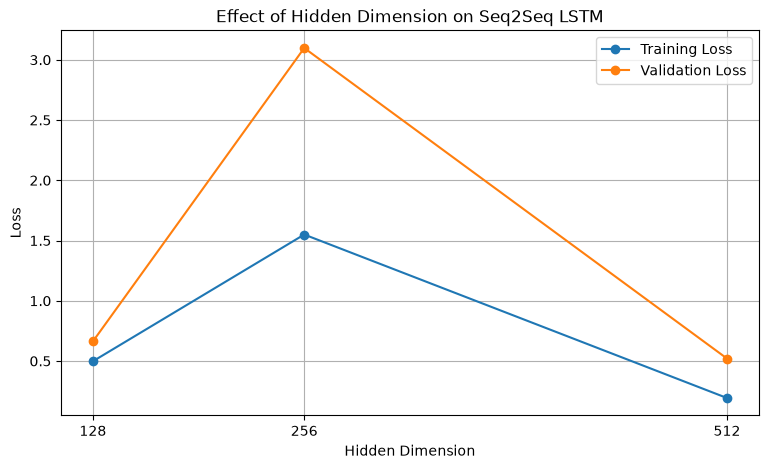

In [98]:
import matplotlib.pyplot as plt

hidden_dimensions = [128, 256, 512]

training_losses = [
    0.4979,
    1.5497,
    0.1932
]

validation_losses = [
    0.6626,
    3.0978,
    0.5209
]

plt.figure(figsize=(9, 5))

plt.plot(
    hidden_dimensions,
    training_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    hidden_dimensions,
    validation_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Hidden Dimension")
plt.ylabel("Loss")
plt.title("Effect of Hidden Dimension on Seq2Seq LSTM")
plt.xticks(hidden_dimensions)
plt.legend()
plt.grid(True)

plt.show()

Question 7

In [99]:

EMBEDDING_DIM = 128
LSTM_UNITS = 256
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 0.001

teacher_forcing_ratios = [0.0, 0.5, 1.0]

print("Teacher Forcing Ratios:", teacher_forcing_ratios)
print("Hidden Units:", LSTM_UNITS)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Teacher Forcing Ratios: [0.0, 0.5, 1.0]
Hidden Units: 256
Embedding Dimension: 128
Batch Size: 64
Epochs: 10


In [100]:
encoder_inputs_0 = Input(shape=(MAX_LENGTH,))

encoder_embedding_0 = Embedding(
    input_dim=len(english_vocab),
    output_dim=EMBEDDING_DIM
)

encoder_embedded_0 = encoder_embedding_0(encoder_inputs_0)

encoder_lstm_0 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

encoder_outputs_0, state_h_0, state_c_0 = encoder_lstm_0(
    encoder_embedded_0
)

decoder_inputs_0 = Input(shape=(MAX_LENGTH - 1,))

decoder_embedding_0 = Embedding(
    input_dim=len(french_vocab),
    output_dim=EMBEDDING_DIM
)

decoder_embedded_0 = decoder_embedding_0(decoder_inputs_0)

decoder_lstm_0 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

decoder_outputs_0, _, _ = decoder_lstm_0(
    decoder_embedded_0,
    initial_state=[state_h_0, state_c_0]
)

decoder_dense_0 = Dense(
    len(french_vocab),
    activation="softmax"
)

predictions_0 = decoder_dense_0(decoder_outputs_0)

model_0 = Model(
    inputs=[encoder_inputs_0, decoder_inputs_0],
    outputs=predictions_0
)

model_0.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_5       │ (None, 29)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 30, 128)   │  1,687,296 │ input_layer_4[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_5         │ (None, 29, 128)   │  2,858,112 │ input_layer_5[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_4 (LSTM)       │ [(None, 30, 256), │    394,240 │ embedding_4[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ [(None, 29, 256), │    394,240 │ embedding_5[0][0… │
│                     │ (None, 256),      │            │ lstm_4[0][1],     │
│                     │ (None, 256)]      │            │ lstm_4[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 29, 22329) │  5,738,553 │ lstm_5[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,072,441 (42.24 MB)

 Trainable params: 11,072,441 (42.24 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
@tf.function
def train_batch_ratio(
    english_input,
    french_input,
    french_target,
    teacher_forcing_ratio
):
    with tf.GradientTape() as tape:

        embedded = encoder_embedding_0(english_input)

        _, hidden_state, cell_state = encoder_lstm_0(
            embedded, training=True
        )

        current_token = french_input[:, 0:1]

        total_loss = 0.0
        total_tokens = 0.0

        for t in range(MAX_LENGTH - 1):

          
            embedded_token = decoder_embedding_0(current_token)

            decoder_output, hidden_state, cell_state = decoder_lstm_0(
                embedded_token,
                initial_state=[hidden_state, cell_state],
                training=True
            )

            predictions = decoder_dense_0(decoder_output)
            predictions = tf.squeeze(predictions, axis=1)

            actual_token = french_target[:, t]

    
            token_loss = loss_function(actual_token, predictions)

            mask = tf.cast(actual_token != PAD_ID, tf.float32)

            total_loss += tf.reduce_sum(token_loss * mask)
            total_tokens += tf.reduce_sum(mask)

        
            if t < MAX_LENGTH - 2:

                predicted_token = tf.argmax(
                    predictions,
                    axis=-1,
                    output_type=tf.int32
                )

                predicted_token = tf.expand_dims(
                    predicted_token, axis=1
                )

                actual_next_token = french_input[:, t + 1:t + 2]

                use_actual = (
                    tf.random.uniform(
                        shape=tf.shape(actual_next_token)
                    ) < teacher_forcing_ratio
                )

                current_token = tf.where(
                    use_actual,
                    actual_next_token,
                    predicted_token
                )

        average_loss = tf.math.divide_no_nan(
            total_loss, total_tokens
        )

    variables = (
        encoder_embedding_0.trainable_variables
        + encoder_lstm_0.trainable_variables
        + decoder_embedding_0.trainable_variables
        + decoder_lstm_0.trainable_variables
        + decoder_dense_0.trainable_variables
    )

    gradients = tape.gradient(average_loss, variables)

    optimizer_0.apply_gradients(zip(gradients, variables))

    return average_loss

In [102]:
optimizer_0 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

In [103]:
optimizer_0 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

print("Optimizer created successfully.")

Optimizer created successfully.


In [104]:
@tf.function
def evaluate_batch_ratio(english_input, french_input, french_target):

    embedded = encoder_embedding_0(english_input)

    _, hidden_state, cell_state = encoder_lstm_0(
        embedded, training=False
    )

    current_token = french_input[:, 0:1]

    total_loss = 0.0
    total_tokens = 0.0

    for t in range(MAX_LENGTH - 1):

        embedded_token = decoder_embedding_0(current_token)

        decoder_output, hidden_state, cell_state = decoder_lstm_0(
            embedded_token,
            initial_state=[hidden_state, cell_state],
            training=False
        )

        predictions = decoder_dense_0(decoder_output)
        predictions = tf.squeeze(predictions, axis=1)

        actual_token = french_target[:, t]

        token_loss = loss_function(actual_token, predictions)

        mask = tf.cast(actual_token != PAD_ID, tf.float32)

        total_loss += tf.reduce_sum(token_loss * mask)
        total_tokens += tf.reduce_sum(mask)

        if t < MAX_LENGTH - 2:

            predicted_token = tf.argmax(
                predictions,
                axis=-1,
                output_type=tf.int32
            )

            current_token = tf.expand_dims(predicted_token, axis=1)

    return tf.math.divide_no_nan(total_loss, total_tokens)


print("Validation function created successfully.")

Validation function created successfully.


In [105]:
import time
import numpy as np

start_time_0 = time.time()

train_losses_0 = []
val_losses_0 = []

for epoch in range(EPOCHS):

    epoch_train_loss = []

    for batch in train_dataset:

        loss_value = train_batch_ratio(
            *batch,
            tf.constant(0.0, dtype=tf.float32)
        )

        epoch_train_loss.append(float(loss_value.numpy()))

    epoch_val_loss = []

    for batch in val_dataset:

        val_loss = evaluate_batch_ratio(*batch)

        epoch_val_loss.append(float(val_loss.numpy()))

    train_loss = float(np.mean(epoch_train_loss))
    val_loss = float(np.mean(epoch_val_loss))

    train_losses_0.append(train_loss)
    val_losses_0.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} - "
        f"Train Loss: {train_loss:.4f} - "
        f"Validation Loss: {val_loss:.4f}"
    )

training_time_0 = (time.time() - start_time_0) / 60

print(f"\nTraining time: {training_time_0:.2f} minutes")

Epoch 1/10 - Train Loss: 4.8153 - Validation Loss: 4.2277
Epoch 2/10 - Train Loss: 3.8858 - Validation Loss: 3.6540
Epoch 3/10 - Train Loss: 3.3289 - Validation Loss: 3.2674
Epoch 4/10 - Train Loss: 2.9273 - Validation Loss: 3.0287
Epoch 5/10 - Train Loss: 2.6305 - Validation Loss: 2.8747
Epoch 6/10 - Train Loss: 2.4001 - Validation Loss: 2.7823
Epoch 7/10 - Train Loss: 2.2169 - Validation Loss: 2.7257
Epoch 8/10 - Train Loss: 2.0687 - Validation Loss: 2.6939
Epoch 9/10 - Train Loss: 1.9452 - Validation Loss: 2.6637
Epoch 10/10 - Train Loss: 1.8419 - Validation Loss: 2.6401

Training time: 374.78 minutes


In [106]:
results_tf_0 = {
    "Teacher Forcing Ratio": 0.0,
    "Training Loss": train_losses_0[-1],
    "Validation Loss": val_losses_0[-1],
    "Training Time (min)": training_time_0
}

print(results_tf_0)

{'Teacher Forcing Ratio': 0.0, 'Training Loss': 1.8419047720011033, 'Validation Loss': 2.6400711276314475, 'Training Time (min)': 374.78206886053084}


In [107]:
encoder_inputs_1 = Input(shape=(MAX_LENGTH,))

encoder_embedding_1 = Embedding(
    input_dim=len(english_vocab),
    output_dim=EMBEDDING_DIM
)

encoder_embedded_1 = encoder_embedding_1(encoder_inputs_1)

encoder_lstm_1 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

encoder_outputs_1, state_h_1, state_c_1 = encoder_lstm_1(
    encoder_embedded_1
)

decoder_inputs_1 = Input(shape=(MAX_LENGTH - 1,))

decoder_embedding_1 = Embedding(
    input_dim=len(french_vocab),
    output_dim=EMBEDDING_DIM
)

decoder_embedded_1 = decoder_embedding_1(decoder_inputs_1)

decoder_lstm_1 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

decoder_outputs_1, _, _ = decoder_lstm_1(
    decoder_embedded_1,
    initial_state=[state_h_1, state_c_1]
)

decoder_dense_1 = Dense(
    len(french_vocab),
    activation="softmax"
)

predictions_1 = decoder_dense_1(decoder_outputs_1)

model_1 = Model(
    inputs=[encoder_inputs_1, decoder_inputs_1],
    outputs=predictions_1
)

model_1.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_7       │ (None, 29)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 30, 128)   │  1,687,296 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_7         │ (None, 29, 128)   │  2,858,112 │ input_layer_7[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_6 (LSTM)       │ [(None, 30, 256), │    394,240 │ embedding_6[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_7 (LSTM)       │ [(None, 29, 256), │    394,240 │ embedding_7[0][0… │
│                     │ (None, 256),      │            │ lstm_6[0][1],     │
│                     │ (None, 256)]      │            │ lstm_6[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 29, 22329) │  5,738,553 │ lstm_7[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,072,441 (42.24 MB)

 Trainable params: 11,072,441 (42.24 MB)

 Non-trainable params: 0 (0.00 B)

In [108]:
optimizer_1 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

print("Optimizer for teacher forcing ratio 1.0 created successfully.")

Optimizer for teacher forcing ratio 1.0 created successfully.


In [109]:
@tf.function
def train_batch_ratio_1(english_input, french_input, french_target):

    with tf.GradientTape() as tape:

        embedded = encoder_embedding_1(english_input)

        _, hidden_state, cell_state = encoder_lstm_1(
            embedded, training=True
        )

        current_token = french_input[:, 0:1]

        total_loss = 0.0
        total_tokens = 0.0

        for t in range(MAX_LENGTH - 1):

            embedded_token = decoder_embedding_1(current_token)

            decoder_output, hidden_state, cell_state = decoder_lstm_1(
                embedded_token,
                initial_state=[hidden_state, cell_state],
                training=True
            )

            predictions = decoder_dense_1(decoder_output)
            predictions = tf.squeeze(predictions, axis=1)

            actual_token = french_target[:, t]

            token_loss = loss_function(actual_token, predictions)

            mask = tf.cast(actual_token != PAD_ID, tf.float32)

            total_loss += tf.reduce_sum(token_loss * mask)
            total_tokens += tf.reduce_sum(mask)

            if t < MAX_LENGTH - 2:
                current_token = french_input[:, t + 1:t + 2]

        average_loss = tf.math.divide_no_nan(
            total_loss, total_tokens
        )

    variables = (
        encoder_embedding_1.trainable_variables
        + encoder_lstm_1.trainable_variables
        + decoder_embedding_1.trainable_variables
        + decoder_lstm_1.trainable_variables
        + decoder_dense_1.trainable_variables
    )

    gradients = tape.gradient(average_loss, variables)

    optimizer_1.apply_gradients(zip(gradients, variables))

    return average_loss


print("Training function for ratio 1.0 created successfully.")

Training function for ratio 1.0 created successfully.


In [111]:
@tf.function
def evaluate_batch_ratio_1(english_input, french_input, french_target):

    embedded = encoder_embedding_1(english_input)

    _, hidden_state, cell_state = encoder_lstm_1(
        embedded, training=False
    )

    current_token = french_input[:, 0:1]

    total_loss = 0.0
    total_tokens = 0.0

    for t in range(MAX_LENGTH - 1):

        embedded_token = decoder_embedding_1(current_token)

        decoder_output, hidden_state, cell_state = decoder_lstm_1(
            embedded_token,
            initial_state=[hidden_state, cell_state],
            training=False
        )

        predictions = decoder_dense_1(decoder_output)
        predictions = tf.squeeze(predictions, axis=1)

        actual_token = french_target[:, t]

        token_loss = loss_function(actual_token, predictions)

        mask = tf.cast(actual_token != PAD_ID, tf.float32)

        total_loss += tf.reduce_sum(token_loss * mask)
        total_tokens += tf.reduce_sum(mask)

        if t < MAX_LENGTH - 2:

            predicted_token = tf.argmax(
                predictions,
                axis=-1,
                output_type=tf.int32
            )

            current_token = tf.expand_dims(predicted_token, axis=1)

    return tf.math.divide_no_nan(total_loss, total_tokens)


print("Validation function for ratio 1.0 created successfully.")

Validation function for ratio 1.0 created successfully.


Question 8

In [112]:
import numpy as np
import pandas as pd

english_pad_id = english_vocab["<PAD>"]
french_pad_id = french_vocab["<PAD>"]

max_lengths = [10, 20, 30]

results_length = []

for max_len in max_lengths:

    english_lengths = np.sum(X_train != english_pad_id, axis=1)
    french_lengths = np.sum(Y_train != french_pad_id, axis=1)

    english_truncated = np.sum(english_lengths > max_len)
    french_truncated = np.sum(french_lengths > max_len)

    results_length.append({
        "Maximum Length": max_len,
        "English Sentences Truncated": int(english_truncated),
        "French Sentences Truncated": int(french_truncated),
        "Total English Sentences": len(X_train),
        "Total French Sentences": len(Y_train)
    })

results_length_df = pd.DataFrame(results_length)

display(results_length_df)

,Maximum Length,English Sentences Truncated,French Sentences Truncated,Total English Sentences,Total French Sentences
0,10,32774,68109,140496,140496
1,20,626,2267,140496,140496
2,30,0,0,140496,140496


In [113]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

def prepare_sequences_for_length(max_len):

    X_train_len = pad_sequences(
        X_train, maxlen=max_len, padding="post",
        truncating="post", value=english_vocab["<PAD>"]
    )

    X_val_len = pad_sequences(
        X_val, maxlen=max_len, padding="post",
        truncating="post", value=english_vocab["<PAD>"]
    )

    X_test_len = pad_sequences(
        X_test, maxlen=max_len, padding="post",
        truncating="post", value=english_vocab["<PAD>"]
    )

    # French sequences
    Y_train_len = pad_sequences(
        Y_train, maxlen=max_len, padding="post",
        truncating="post", value=french_vocab["<PAD>"]
    )

    Y_val_len = pad_sequences(
        Y_val, maxlen=max_len, padding="post",
        truncating="post", value=french_vocab["<PAD>"]
    )

    Y_test_len = pad_sequences(
        Y_test, maxlen=max_len, padding="post",
        truncating="post", value=french_vocab["<PAD>"]
    )

    return (
        X_train_len, X_val_len, X_test_len,
        Y_train_len, Y_val_len, Y_test_len
    )


sequence_data = {}

for length in [10, 20, 30]:

    sequence_data[length] = prepare_sequences_for_length(length)

    print(f"Maximum Length: {length}")
    print("Training English:", sequence_data[length][0].shape)
    print("Training French:", sequence_data[length][3].shape)
    print()

Maximum Length: 10
Training English: (140496, 10)
Training French: (140496, 10)

Maximum Length: 20
Training English: (140496, 20)
Training French: (140496, 20)

Maximum Length: 30
Training English: (140496, 30)
Training French: (140496, 30)



In [114]:
decoder_data = {}

for length in [10, 20, 30]:

    Y_train_len = sequence_data[length][3]
    Y_val_len = sequence_data[length][4]
    Y_test_len = sequence_data[length][5]

    decoder_data[length] = {
        "train_input": Y_train_len[:, :-1],
        "train_target": Y_train_len[:, 1:],
        "val_input": Y_val_len[:, :-1],
        "val_target": Y_val_len[:, 1:],
        "test_input": Y_test_len[:, :-1],
        "test_target": Y_test_len[:, 1:]
    }

    print(f"Maximum Length: {length}")
    print("Decoder input:", decoder_data[length]["train_input"].shape)
    print("Decoder target:", decoder_data[length]["train_target"].shape)
    print()

Maximum Length: 10
Decoder input: (140496, 9)
Decoder target: (140496, 9)

Maximum Length: 20
Decoder input: (140496, 19)
Decoder target: (140496, 19)

Maximum Length: 30
Decoder input: (140496, 29)
Decoder target: (140496, 29)



In [115]:
sample_weights_length = {}

for length in [10, 20, 30]:

    train_target = decoder_data[length]["train_target"]
    val_target = decoder_data[length]["val_target"]

    sample_weights_length[length] = {
        "train": (train_target != PAD_ID).astype("float32"),
        "val": (val_target != PAD_ID).astype("float32")
    }

    print(f"Maximum Length: {length}")
    print(
        "Training mask shape:",
        sample_weights_length[length]["train"].shape
    )
    print(
        "Validation mask shape:",
        sample_weights_length[length]["val"].shape
    )
    print()

Maximum Length: 10
Training mask shape: (140496, 9)
Validation mask shape: (28100, 9)

Maximum Length: 20
Training mask shape: (140496, 19)
Validation mask shape: (28100, 19)

Maximum Length: 30
Training mask shape: (140496, 29)
Validation mask shape: (28100, 29)



In [116]:
MAX_LENGTH_10 = 10


encoder_inputs_10 = Input(shape=(MAX_LENGTH_10,))

encoder_embedding_10 = Embedding(
    input_dim=len(english_vocab),
    output_dim=EMBEDDING_DIM
)

encoder_embedded_10 = encoder_embedding_10(encoder_inputs_10)

encoder_lstm_10 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

_, state_h_10, state_c_10 = encoder_lstm_10(
    encoder_embedded_10
)

decoder_inputs_10 = Input(shape=(MAX_LENGTH_10 - 1,))

decoder_embedding_10 = Embedding(
    input_dim=len(french_vocab),
    output_dim=EMBEDDING_DIM
)

decoder_embedded_10 = decoder_embedding_10(decoder_inputs_10)

decoder_lstm_10 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

decoder_outputs_10, _, _ = decoder_lstm_10(
    decoder_embedded_10,
    initial_state=[state_h_10, state_c_10]
)

decoder_dense_10 = Dense(
    len(french_vocab),
    activation="softmax"
)

predictions_10 = decoder_dense_10(decoder_outputs_10)

model_10 = Model(
    inputs=[encoder_inputs_10, decoder_inputs_10],
    outputs=predictions_10
)

model_10.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_9       │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_8         │ (None, 10, 128)   │  1,687,296 │ input_layer_8[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_9         │ (None, 9, 128)    │  2,858,112 │ input_layer_9[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_8 (LSTM)       │ [(None, 10, 256), │    394,240 │ embedding_8[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_9 (LSTM)       │ [(None, 9, 256),  │    394,240 │ embedding_9[0][0… │
│                     │ (None, 256),      │            │ lstm_8[0][1],     │
│                     │ (None, 256)]      │            │ lstm_8[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 9, 22329)  │  5,738,553 │ lstm_9[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,072,441 (42.24 MB)

 Trainable params: 11,072,441 (42.24 MB)

 Non-trainable params: 0 (0.00 B)

In [117]:
optimizer_10 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

model_10.compile(
    optimizer=optimizer_10,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    weighted_metrics=[]
)

print("10-token model compiled successfully.")

10-token model compiled successfully.


In [118]:
start_time_10 = time.time()

history_10 = model_10.fit(
    [sequence_data[10][0], decoder_data[10]["train_input"]],
    decoder_data[10]["train_target"],
    sample_weight=sample_weights_length[10]["train"],
    validation_data=(
        [sequence_data[10][1], decoder_data[10]["val_input"]],
        decoder_data[10]["val_target"],
        sample_weights_length[10]["val"]
    ),
    batch_size=BATCH_SIZE,
    epochs=3,
    verbose=1
)

training_time_10 = (time.time() - start_time_10) / 60

print(f"\n10-token training time: {training_time_10:.2f} minutes")

Epoch 1/3
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 356s 161ms/step - loss: 3.7734 - val_loss: 2.9304
Epoch 2/3
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 352s 160ms/step - loss: 2.5114 - val_loss: 2.2922
Epoch 3/3
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 359s 163ms/step - loss: 1.9531 - val_loss: 1.9390

10-token training time: 17.79 minutes


In [ ]:
MAX_LENGTH_20 = 20
encoder_inputs_20 = Input(shape=(MAX_LENGTH_20,))

encoder_embedding_20 = Embedding(
    input_dim=len(english_vocab),
    output_dim=EMBEDDING_DIM
)

encoder_embedded_20 = encoder_embedding_20(encoder_inputs_20)

encoder_lstm_20 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

_, state_h_20, state_c_20 = encoder_lstm_20(
    encoder_embedded_20
)

decoder_inputs_20 = Input(shape=(MAX_LENGTH_20 - 1,))

decoder_embedding_20 = Embedding(
    input_dim=len(french_vocab),
    output_dim=EMBEDDING_DIM
)

decoder_embedded_20 = decoder_embedding_20(decoder_inputs_20)

decoder_lstm_20 = LSTM(
    LSTM_UNITS,
    return_sequences=True,
    return_state=True,
    dropout=0.0
)

decoder_outputs_20, _, _ = decoder_lstm_20(
    decoder_embedded_20,
    initial_state=[state_h_20, state_c_20]
)

decoder_dense_20 = Dense(
    len(french_vocab),
    activation="softmax"
)

predictions_20 = decoder_dense_20(decoder_outputs_20)

model_20 = Model(
    inputs=[encoder_inputs_20, decoder_inputs_20],
    outputs=predictions_20
)

model_20.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_11      │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_10        │ (None, 20, 128)   │  1,687,296 │ input_layer_10[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_11        │ (None, 19, 128)   │  2,858,112 │ input_layer_11[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_10 (LSTM)      │ [(None, 20, 256), │    394,240 │ embedding_10[0][… │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_11 (LSTM)      │ [(None, 19, 256), │    394,240 │ embedding_11[0][… │
│                     │ (None, 256),      │            │ lstm_10[0][1],    │
│                     │ (None, 256)]      │            │ lstm_10[0][2]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 19, 22329) │  5,738,553 │ lstm_11[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,072,441 (42.24 MB)

 Trainable params: 11,072,441 (42.24 MB)

 Non-trainable params: 0 (0.00 B)

In [120]:
optimizer_20 = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

model_20.compile(
    optimizer=optimizer_20,
    loss=tf.keras.losses.SparseCategoricalCrossentropy()
)

print("20-token model compiled successfully.")

20-token model compiled successfully.


In [121]:
start_time_20 = time.time()

history_20 = model_20.fit(
    [sequence_data[20][0], decoder_data[20]["train_input"]],
    decoder_data[20]["train_target"],
    sample_weight=sample_weights_length[20]["train"],
    validation_data=(
        [sequence_data[20][1], decoder_data[20]["val_input"]],
        decoder_data[20]["val_target"],
        sample_weights_length[20]["val"]
    ),
    batch_size=BATCH_SIZE,
    epochs=3,
    verbose=1
)

training_time_20 = (time.time() - start_time_20) / 60

print(f"\n20-token training time: {training_time_20:.2f} minutes")

Epoch 1/3
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 786s 355ms/step - loss: 2.0194 - val_loss: 1.5650
Epoch 2/3
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 895s 397ms/step - loss: 1.3653 - val_loss: 1.2647
Epoch 3/3
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 788s 359ms/step - loss: 1.0924 - val_loss: 1.0863

20-token training time: 41.13 minutes


In [122]:
import pandas as pd
import numpy as np

PAD_EN = english_vocab["<PAD>"]
PAD_FR = french_vocab["<PAD>"]

truncation_results = []

for split_name, X, Y in [
    ("Train", X_train, Y_train),
    ("Validation", X_val, Y_val),
    ("Test", X_test, Y_test)
]:
    english_lengths = np.sum(X != PAD_EN, axis=1)
    french_lengths = np.sum(Y != PAD_FR, axis=1)

    for max_len in [10, 20, 30]:
        truncation_results.append({
            "Dataset": split_name,
            "Max Length": max_len,
            "English Sentences Truncated": int(np.sum(english_lengths > max_len)),
            "French Sentences Truncated": int(np.sum(french_lengths > max_len))
        })

truncation_df = pd.DataFrame(truncation_results)
display(truncation_df)

,Dataset,Max Length,English Sentences Truncated,French Sentences Truncated
0,Train,10,32774,68109
1,Train,20,626,2267
2,Train,30,0,0
3,Validation,10,6539,13679
4,Validation,20,109,454
5,Validation,30,0,0
6,Test,10,1655,3503
7,Test,20,34,141
8,Test,30,0,0


In [123]:
def greedy_decode_full_model(model, english_sequence, max_len):
    source = pad_sequences(
        [english_sequence],
        maxlen=max_len,
        padding="post",
        truncating="post",
        value=english_vocab["<PAD>"]
    )

    decoder_input = np.zeros((1, max_len - 1), dtype="int32")
    decoder_input[0, 0] = SOS_ID

    predicted_tokens = []

    for step in range(max_len - 1):
        predictions = model.predict(
            [source, decoder_input], verbose=0
        )

        predicted_id = int(np.argmax(predictions[0, step]))

        if predicted_id == EOS_ID:
            break

        predicted_tokens.append(predicted_id)

        if step + 1 < max_len - 1:
            decoder_input[0, step + 1] = predicted_id

    return " ".join(
        french_id_to_word.get(token, "<UNK>")
        for token in predicted_tokens
    )


for i in range(5):
    print(f"\nExample {i + 1}")
    print("English :", sequence_to_sentence(X_test[i], english_id_to_word))
    print("Reference:", sequence_to_sentence(Y_test[i], french_id_to_word))
    print("10-token :", greedy_decode_full_model(model_10, X_test[i], 10))
    print("20-token :", greedy_decode_full_model(model_20, X_test[i], 20))
    print("30-token :", greedy_decode(X_test[i]))


Example 1
English : whenever i go to a japanese restaurant , i take the disposable chopsticks home with me .
Reference: à chaque fois que je vais au restaurant japonais , j ' emporte les baguettes chez moi .
10-token : à un moment , je vais aller au cinéma
20-token : lorsque j ' ai été un peu fatigué pour la première fois , je vous ai mis le travail
30-token : chaque que je veux être ma vie , ma mère , ma vie est dans un restaurant .

Example 2
English : she borrowed the book from him many years ago and hasn ' t yet returned it .
Reference: elle lui a emprunté le livre il y a de nombreuses années et ne l ' a toujours pas rendu .
10-token : elle a rencontré le livre que ce qu '
20-token : elle a l ' air si longtemps que l ' autre a eu le plus de temps que le
30-token : elle a emprunté le livre depuis il y avait trois ans , mais il ne savait .

Example 3
English : where ' s the dog ?
Reference: où est le chien ?
10-token : où est le chien ?
20-token : où est le livre ?
30-token : où est

Question 9

In [124]:
test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, decoder_input_test, decoder_target_test)
).batch(BATCH_SIZE)

test_batch_losses = []

for encoder_batch, decoder_input_batch, decoder_target_batch in test_dataset:
    batch_loss = evaluate_batch(
        encoder_batch,
        decoder_input_batch,
        decoder_target_batch
    )
    test_batch_losses.append(float(batch_loss.numpy()))

test_loss = np.mean(test_batch_losses)

print(f"Test Loss: {test_loss:.4f}")

Test Loss: 3.1195


In [125]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

all_references = []
all_hypotheses = []

test_source_dataset = tf.data.Dataset.from_tensor_slices(
    X_test
).batch(BATCH_SIZE)

for source_batch in test_source_dataset:

    source_embedded = encoder_embedding(source_batch)
    _, hidden_state, cell_state = encoder_lstm(
        source_embedded, training=False
    )

    batch_size = tf.shape(source_batch)[0]
    current_token = tf.fill([batch_size, 1], SOS_ID)

    finished = np.zeros(int(batch_size.numpy()), dtype=bool)
    generated = [[] for _ in range(int(batch_size.numpy()))]

    for step in range(MAX_LENGTH - 1):

        embedded_token = decoder_embedding_layer(current_token)

        decoder_output, hidden_state, cell_state = decoder_lstm(
            embedded_token,
            initial_state=[hidden_state, cell_state],
            training=False
        )

        predictions = decoder_dense(decoder_output)
        predicted_ids = tf.argmax(
            predictions[:, 0, :], axis=-1
        ).numpy()

        for i, token_id in enumerate(predicted_ids):
            if not finished[i]:
                if token_id == EOS_ID:
                    finished[i] = True
                else:
                    generated[i].append(int(token_id))

        predicted_ids[finished] = EOS_ID
        current_token = tf.convert_to_tensor(
            predicted_ids.reshape(-1, 1), dtype=tf.int32
        )

        if finished.all():
            break

    for tokens in generated:
        all_hypotheses.append([
            french_id_to_word.get(token, "<UNK>")
            for token in tokens
        ])

for sentence in Y_test:
    reference = sequence_to_sentence(
        sentence, french_id_to_word
    )
    all_references.append([reference.split()])

bleu_score = corpus_bleu(
    all_references,
    all_hypotheses,
    smoothing_function=SmoothingFunction().method1
)

print("Number of test translations:", len(all_hypotheses))
print(f"Corpus BLEU Score: {bleu_score:.4f}")
print(f"Corpus BLEU Score (%): {bleu_score * 100:.2f}")

Number of test translations: 7025
Corpus BLEU Score: 0.2927
Corpus BLEU Score (%): 29.27


In [126]:
for i in range(10):
    english_sentence = sequence_to_sentence(
        X_test[i], english_id_to_word
    )

    reference_sentence = " ".join(all_references[i][0])
    predicted_sentence = " ".join(all_hypotheses[i])

    print(f"\nExample {i + 1}")
    print("English   :", english_sentence)
    print("Reference :", reference_sentence)
    print("Predicted :", predicted_sentence)
    print("-" * 80)


Example 1
English   : whenever i go to a japanese restaurant , i take the disposable chopsticks home with me .
Reference : à chaque fois que je vais au restaurant japonais , j ' emporte les baguettes chez moi .
Predicted : chaque que je veux être ma vie , ma mère , ma vie est dans un restaurant .
--------------------------------------------------------------------------------

Example 2
English   : she borrowed the book from him many years ago and hasn ' t yet returned it .
Reference : elle lui a emprunté le livre il y a de nombreuses années et ne l ' a toujours pas rendu .
Predicted : elle a emprunté le livre depuis il y avait trois ans , mais il ne savait .
--------------------------------------------------------------------------------

Example 3
English   : where ' s the dog ?
Reference : où est le chien ?
Predicted : où est le chien ?
--------------------------------------------------------------------------------

Example 4
English   : all i want is a washing machine .
Reference

Question 10

In [127]:
real_world_sentences = [
    "I drink a cup of tea every morning.",
    "My brother is learning how to drive.",
    "The children are playing in the garden.",
    "We visited the museum last Sunday.",
    "She forgot to bring her umbrella.",
    "Please close the window before you leave.",
    "I will call you after the meeting.",
    "They are planning a trip to France.",
    "The train arrived twenty minutes late.",
    "He enjoys reading books about science.",
    "My mother makes delicious food.",
    "Can you help me with this problem?",
    "The weather is beautiful today.",
    "I have never visited this city before.",
    "She bought a new laptop yesterday.",
    "We should protect the environment.",
    "The students are preparing for their exams.",
    "He was watching television when I arrived.",
    "I want to improve my programming skills.",
    "Learning a new language takes time and practice."
]

reference_french = [
    "Je bois une tasse de thé chaque matin.",
    "Mon frère apprend à conduire.",
    "Les enfants jouent dans le jardin.",
    "Nous avons visité le musée dimanche dernier.",
    "Elle a oublié d'apporter son parapluie.",
    "Veuillez fermer la fenêtre avant de partir.",
    "Je t'appellerai après la réunion.",
    "Ils prévoient un voyage en France.",
    "Le train est arrivé avec vingt minutes de retard.",
    "Il aime lire des livres sur la science.",
    "Ma mère prépare de délicieux plats.",
    "Peux-tu m'aider avec ce problème ?",
    "Il fait beau aujourd'hui.",
    "Je n'ai jamais visité cette ville auparavant.",
    "Elle a acheté un nouvel ordinateur portable hier.",
    "Nous devrions protéger l'environnement.",
    "Les étudiants se préparent pour leurs examens.",
    "Il regardait la télévision quand je suis arrivé.",
    "Je veux améliorer mes compétences en programmation.",
    "Apprendre une nouvelle langue demande du temps et de la pratique."
]

print("Number of original sentences:", len(real_world_sentences))
print("Number of reference translations:", len(reference_french))

Number of original sentences: 20
Number of reference translations: 20


In [129]:
import re
from tensorflow.keras.preprocessing.sequence import pad_sequences

def tokenize(sentence):
    return re.findall(
        r"\w+|[^\w\s]",
        sentence.lower(),
        flags=re.UNICODE
    )

real_world_predictions = []

for sentence in real_world_sentences:

    tokens = tokenize(sentence)

    sequence = [
        english_vocab.get(token, english_vocab["<UNK>"])
        for token in tokens
    ]

    sequence.append(english_vocab["<EOS>"])

    sequence = pad_sequences(
        [sequence],
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post",
        value=english_vocab["<PAD>"]
    )[0]

    prediction = greedy_decode(sequence)
    real_world_predictions.append(prediction)

print("Generated translations:", len(real_world_predictions))

Generated translations: 20


In [130]:
real_world_results = pd.DataFrame({
    "No.": range(1, 21),
    "English Sentence": real_world_sentences,
    "Reference French": reference_french,
    "Predicted French": real_world_predictions
})

pd.set_option("display.max_colwidth", None)
display(real_world_results)

,No.,English Sentence,Reference French,Predicted French
0,1,I drink a cup of tea every morning.,Je bois une tasse de thé chaque matin.,je bois un tasse de café dans le café .
1,2,My brother is learning how to drive.,Mon frère apprend à conduire.,mon frère a à conduire .
2,3,The children are playing in the garden.,Les enfants jouent dans le jardin.,les enfants jouent dans le jardin .
3,4,We visited the museum last Sunday.,Nous avons visité le musée dimanche dernier.,nous avons visité le musée le dimanche dernier .
4,5,She forgot to bring her umbrella.,Elle a oublié d'apporter son parapluie.,elle a oublié de peindre son parapluie .
...,...,...,...,...
15,16,We should protect the environment.,Nous devrions protéger l'environnement.,nous devrions respecter la . .
16,17,The students are preparing for their exams.,Les étudiants se préparent pour leurs examens.,les étudiants sont des des en .
17,18,He was watching television when I arrived.,Il regardait la télévision quand je suis arrivé.,"il porte la radio la télévision , ."
18,19,I want to improve my programming skills.,Je veux améliorer mes compétences en programmation.,je veux me mettre au basket - ball .
